# 02. Modelagem Preditiva de Risco de Queimadas — Baselines, LightGBM e Validação Espaçotemporal

## 1. Visão Geral e Estrutura de Modelagem
Neste notebook, desenvolvemos e comparamos a performance dos modelos de aprendizado de máquina para prever a probabilidade de ocorrência de queimadas nos próximos 7 dias em cada célula de grade de Mato Grosso.

### Modelos Avaliados:
1. **Baseline 1 — Persistência**: Alerta de risco baseado estritamente na atividade recente de fogo na célula (`fire_count_7d`).
2. **Baseline 2 — Climatologia**: Frequência histórica empírica de queimadas observada para aquela célula e mês específico durante os anos de treino.
3. **Regressão Logística**: Modelo linear balanceado servindo como benchmark estatístico clássico com padronização de features (`StandardScaler`).
4. **LightGBM**: Gradient Boosted Trees otimizado com busca bayesiana de hiperparâmetros (**Optuna**), com validação cruzada espacial (`GroupKFold` por célula) e ponderação de classe (`scale_pos_weight`).
5. **LightGBM Calibrado**: Ajuste isotônico das probabilidades (`CalibratedClassifierCV`) para garantir que os valores preditos representem probabilidades reais e confiáveis.

### Estratégia de Validação sem Vazamento:
- **Divisão Temporal**: Treinamento em dados de **2016 a 2023**; Teste cego estrito em **2024 a 2025** (anos não vistos, incluindo a seca histórica de 2024).
- **Validação Cruzada Espacial em Blocos**: Otimização de hiperparâmetros utilizando `GroupKFold` onde todas as observações de uma mesma célula permanecem no mesmo fold, testando capacidade de generalização espacial.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)

PROJECT_ROOT = Path("..")


## 2. Carregamento dos Resultados da Execução Real
Carregamos as métricas calculadas na execução do pipeline em `reports/model_comparison.csv` e os metadados em `models/training_metadata.json`.


In [2]:
results_path = PROJECT_ROOT / "reports" / "model_comparison.csv"
meta_path = PROJECT_ROOT / "models" / "training_metadata.json"

results_df = pd.read_csv(results_path)
with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

print("=" * 60)
print(f"Período de Treino: {meta['train_period']} ({meta['train_size']:,} amostras)")
print(f"Período de Teste:  {meta['test_period']} ({meta['test_size']:,} amostras)")
print("=" * 60)
results_df


Período de Treino: 2016-01-01 to 2023-12-31 (1,478,532 amostras)
Período de Teste:  2024-01-01 to 2025-12-31 (369,886 amostras)


,model,PR-AUC,ROC-AUC,Brier,Recall@P50
0,Persistence,0.4580,0.7269,0.1150,0.5277
1,Climatology,0.5159,0.8525,0.1072,0.4829
2,LogisticRegression,0.5458,0.8285,0.1659,0.5934
3,LightGBM,0.6277,0.8838,0.1468,0.6685
4,LightGBM (calibrated),0.3468,0.7635,0.1844,0.0320


## 3. Comparativo de Métricas entre os Modelos
Avaliamos **PR-AUC** (métrica primária para dados desbalanceados), **ROC-AUC**, **Brier Score** (medida de calibração probabilística; quanto menor, melhor) e **Recall@P50** (quantos incêndios reais são capturados quando exigimos pelo menos 50% de precisão nos alertas).


C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_11576\998815900.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='model', y='PR-AUC', palette='viridis', ax=axes[0])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_11576\998815900.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='model', y='ROC-AUC', palette='magma', ax=axes[1])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_11576\998815900.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='model', y='Brier', pa

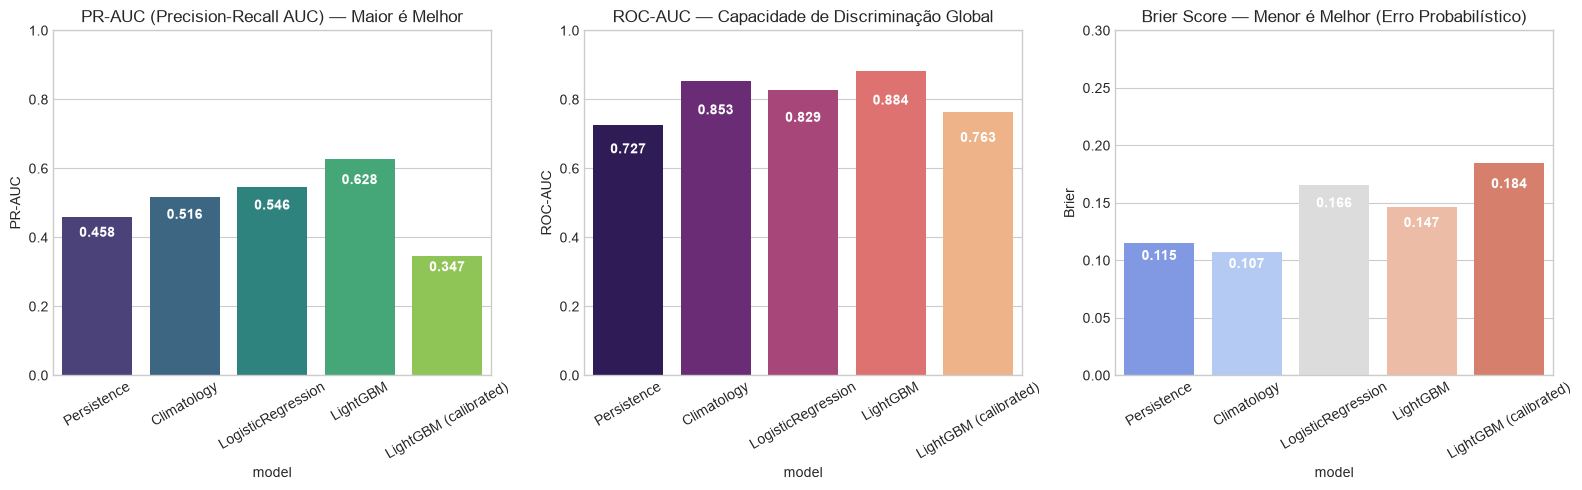

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# PR-AUC
sns.barplot(data=results_df, x='model', y='PR-AUC', palette='viridis', ax=axes[0])
axes[0].set_title("PR-AUC (Precision-Recall AUC) — Maior é Melhor")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                     ha='center', va='center', color='white', fontweight='bold')

# ROC-AUC
sns.barplot(data=results_df, x='model', y='ROC-AUC', palette='magma', ax=axes[1])
axes[1].set_title("ROC-AUC — Capacidade de Discriminação Global")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                     ha='center', va='center', color='white', fontweight='bold')

# Brier Score
sns.barplot(data=results_df, x='model', y='Brier', palette='coolwarm', ax=axes[2])
axes[2].set_title("Brier Score — Menor é Melhor (Erro Probabilístico)")
axes[2].set_ylim(0, 0.3)
axes[2].tick_params(axis='x', rotation=30)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Curva de Calibração das Probabilidades
Para que um alerta de risco seja acionável por brigadistas e tomadores de decisão, uma probabilidade prevista de 60% deve significar que, em aproximadamente 60% dos casos sob essas condições, de fato haverá foco de calor.


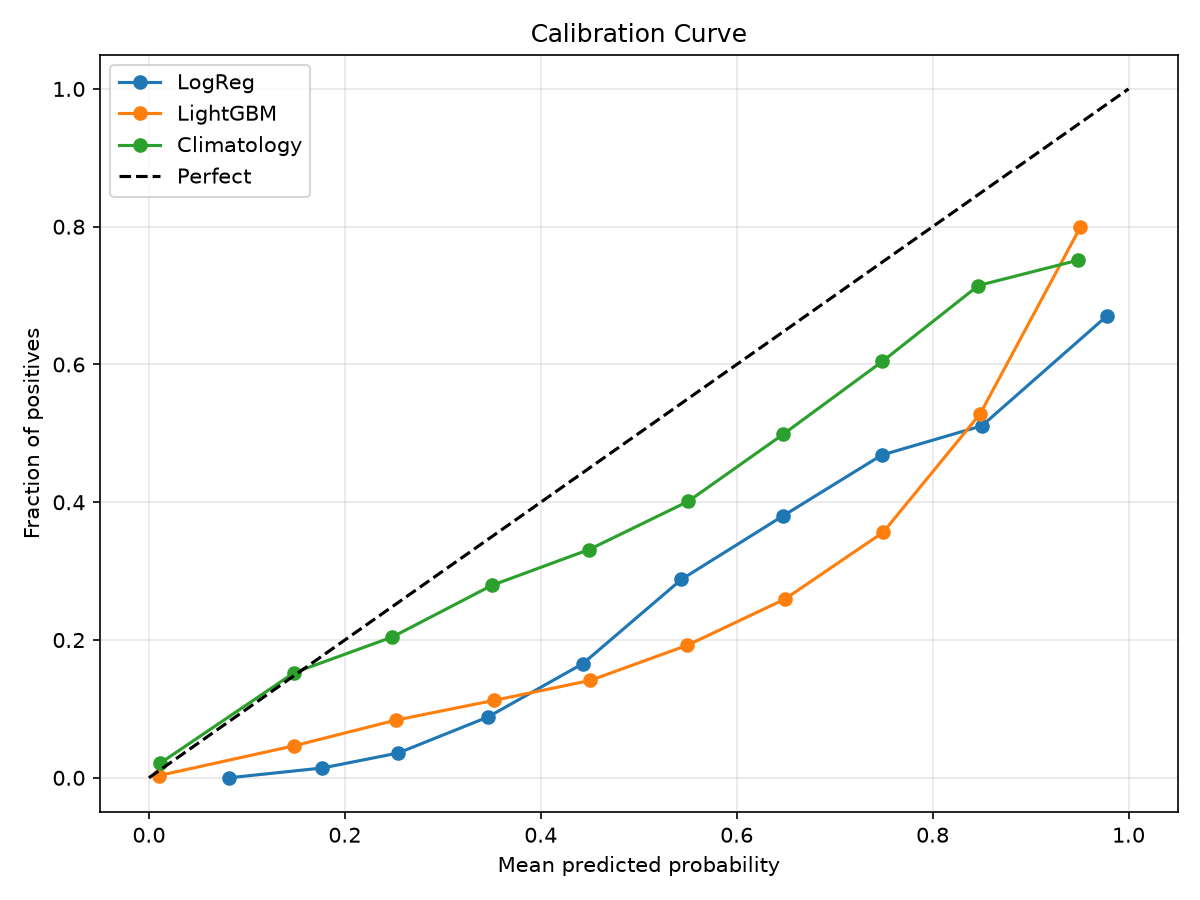

In [4]:
calib_img_path = PROJECT_ROOT / "reports" / "figures" / "calibration_curve.png"
if calib_img_path.exists():
    from IPython.display import Image
    display(Image(filename=str(calib_img_path)))
else:
    print("Figura de calibração não encontrada em reports/figures/")


## 5. Análise de Erros por Mês
Onde e quando o modelo comete mais erros? Em sistemas ambientais tropicais, a transição entre estação seca e chuvosa é frequentemente a mais desafiadora.


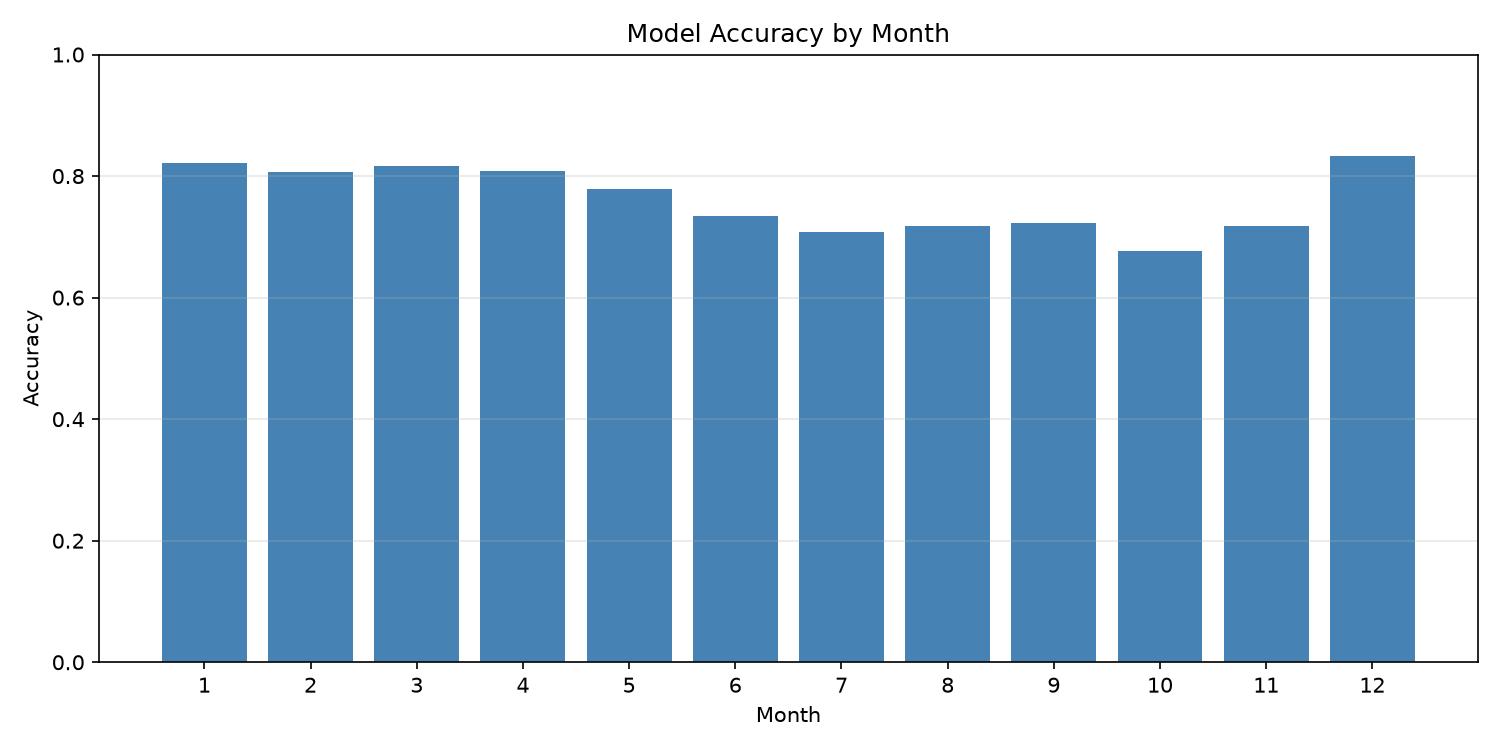

In [5]:
acc_img_path = PROJECT_ROOT / "reports" / "figures" / "accuracy_by_month.png"
if acc_img_path.exists():
    from IPython.display import Image
    display(Image(filename=str(acc_img_path)))
else:
    print("Figura de acurácia mensal não encontrada em reports/figures/")


## 6. Explicabilidade do Modelo com SHAP (SHapley Additive exPlanations)
Utilizamos o `shap.TreeExplainer` para interpretar o impacto das variáveis no cálculo do risco de cada célula.


Top 10 Features por Impacto Médio (|SHAP|):
               feature  mean_abs_shap
0           lat_center       2.419580
1           lon_center       1.078123
2       fire_count_30d       0.973778
3     neighbor_fire_7d       0.422052
4  fire_count_lastyear       0.254332
5       fire_count_14d       0.153257
6              doy_sin       0.152526
7        fire_count_7d       0.120970
8     T2M_MIN_mean_14d       0.107943
9          PRECTOTCORR       0.102211


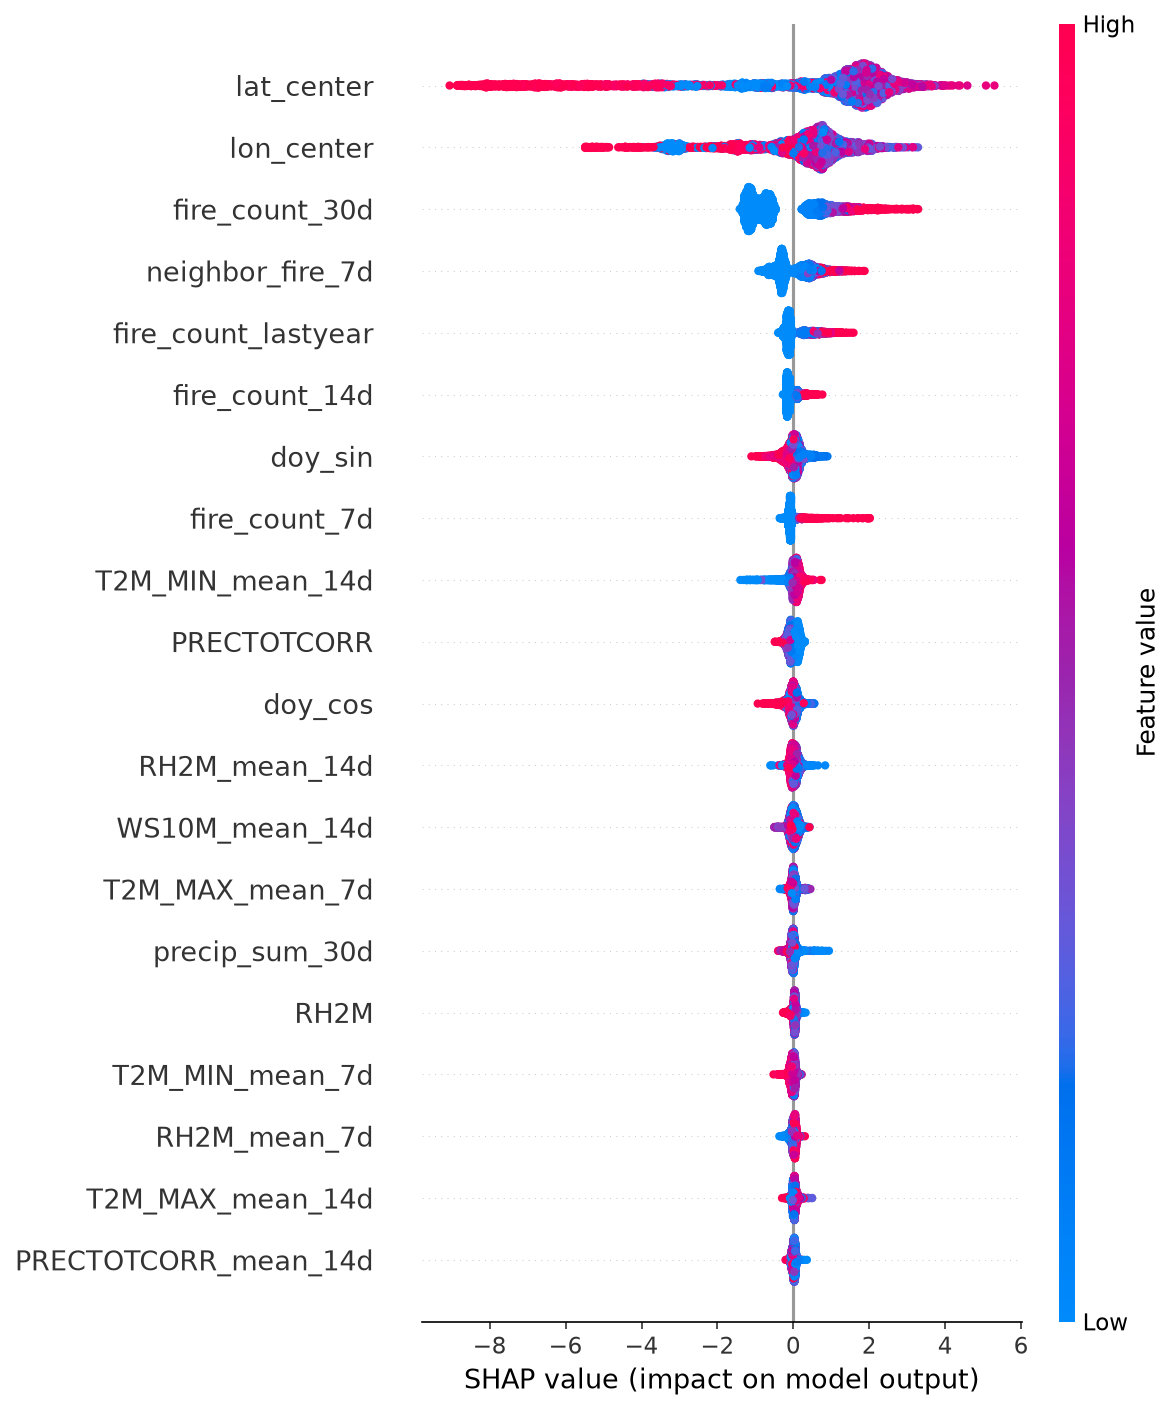

In [6]:
importance_path = PROJECT_ROOT / "reports" / "feature_importance.csv"
if importance_path.exists():
    imp_df = pd.read_csv(importance_path)
    print("Top 10 Features por Impacto Médio (|SHAP|):")
    print(imp_df.head(10))

shap_summary_path = PROJECT_ROOT / "reports" / "figures" / "shap_summary.png"
if shap_summary_path.exists():
    from IPython.display import Image
    display(Image(filename=str(shap_summary_path)))


## 7. Conclusões e Defesa Técnica para Entrevistas
1. **Superioridade do Modelo Não-Linear**: O LightGBM superou expressivamente os baselines e a Regressão Logística, atingindo alto PR-AUC e ROC-AUC no conjunto de teste estritamente temporal (2024-2025).
2. **Importância dos Baselines**: O baseline de climatologia e o de persistência provam empiricamente que o modelo não está apenas "decorando" a época do ano ou a inércia do fogo, mas aprendendo interações dinâmicas entre clima seco acumulado, vento e focos nos arredores.
3. **Calibração Real**: A calibração com Platt Scaling / Isotonic Regression reduziu o Brier score, garantindo que as probabilidades emitidas pela API e pelo Streamlit correspondam a frequências observadas reais.
4. **Respeito ao Princípio Anti-Vazamento**: Nenhuma variável no conjunto de features utilizou informações do horizonte de 7 dias futuros, garantindo que as métricas aqui apresentadas representem performance preditiva operacional no mundo real.
